# code for converting heliocentric to carrington map for callibrated Cak

In [1]:
import pandas as pd
import os
import numpy as np
import h5py
import matplotlib.pyplot as plt
from datetime import datetime
from astropy.time import Time
from astropy.io import fits
from sunpy.coordinates import sun
from scipy.interpolate import griddata
from datetime import datetime, timedelta
from skimage.transform import resize

In [2]:
# List to collect rows
rows = []

for year in range(1900, 2005):   # inclusive 1975 → 2003
    for month in range(1, 13):   # full 12 months
        image_path = f"/home/iron-man/Documents/long_term_reconstruction/callibrated/Cak_Rotated/{year}/{month:02d}"
        # image_path = f"/home/rohan/Documents/data/callibrated/Cak_Rotated_new_all_cak/{year}/{month:02d}"  
        if os.path.exists(image_path): 
            contents = os.listdir(image_path)
            for content in contents:
                file_name = content.split(".")[0]     # e.g. 19750113_0218
                if "_" not in file_name:
                    continue  # skip unexpected files
                date = file_name.split('_')[0]        # 19750113
                time = file_name.split('_')[1]        # 0218

                # build datetime safely
                try:
                    dt = datetime.strptime(date + time, "%Y%m%d%H%M")
                    year_start = datetime(dt.year, 1, 1)
                    year_end = datetime(dt.year + 1, 1, 1)

                    decimal_year = dt.year + (dt - year_start).total_seconds() / (year_end - year_start).total_seconds()
                except ValueError:
                    continue  # skip malformed filenames

                rows.append({
                    "year": dt.year,
                    "month": dt.month,
                    "day": dt.day,
                    "hour": dt.hour,
                    "minute": dt.minute,
                    "datetime": dt,
                    "Date" : decimal_year,
                    "value": file_name
                })

# Convert to DataFrame
df = pd.DataFrame(rows)

# Save to CSV
df.to_csv("cak_data_paths.csv", index=False)

print("Saved cak_data_paths.csv with", len(df), "rows")
df.head()


Saved cak_data_paths.csv with 44216 rows


,year,month,day,hour,minute,datetime,Date,value
0,1907,2,12,10,6,1907-02-12 10:06:00,1907.116221,19070212_1006
1,1907,2,14,8,23,1907-02-14 08:23:00,1907.121505,19070214_0823
2,1907,2,24,8,32,1907-02-24 08:32:00,1907.148919,19070224_0832
3,1907,2,13,9,36,1907-02-13 09:36:00,1907.118904,19070213_0936
4,1907,2,24,8,37,1907-02-24 08:37:00,1907.148929,19070224_0837


In [3]:
df_unique = df.drop_duplicates(subset=["year", "month", "day"])
df_unique


,year,month,day,hour,minute,datetime,Date,value
0,1907,2,12,10,6,1907-02-12 10:06:00,1907.116221,19070212_1006
1,1907,2,14,8,23,1907-02-14 08:23:00,1907.121505,19070214_0823
2,1907,2,24,8,32,1907-02-24 08:32:00,1907.148919,19070224_0832
3,1907,2,13,9,36,1907-02-13 09:36:00,1907.118904,19070213_0936
5,1907,2,22,8,40,1907-02-22 08:40:00,1907.143455,19070222_0840
...,...,...,...,...,...,...,...,...
44211,2003,12,31,2,26,2003-12-31 02:26:00,2003.997538,20031231_0226
44212,2003,12,28,2,25,2003-12-28 02:25:00,2003.989317,20031228_0225
44213,2003,12,7,2,49,2003-12-07 02:49:00,2003.931828,20031207_0249
44214,2003,12,18,5,2,2003-12-18 05:02:00,2003.962218,20031218_0502


In [4]:
df1 = pd.read_csv("/home/iron-man/Documents/long_term_reconstruction/carrington_rotation_start_dates.csv")
# filter all rows where Year is between 1975 and 2003
df1 = df1.loc[(df1["Year"] >= 1900) & (df1["Year"] <= 2005)].reset_index(drop=True)

# check the result
print(df1)
# df1["Rotation"].iloc[300]

      Rotation  Year  Month      Day        Date   Julian Date
0          619  1900      1   4.0862  1900.00846  2.415024e+06
1          620  1900      1  31.4267  1900.08336  2.415051e+06
2          621  1900      2  27.7648  1900.15826  2.415078e+06
3          622  1900      3  27.0782  1900.23309  2.415106e+06
4          623  1900      4  23.3502  1900.30781  2.415133e+06
...        ...   ...    ...      ...         ...           ...
1415      2034  2005      9   4.4215  2005.67513  2.453618e+06
1416      2035  2005     10   1.6920  2005.74984  2.453645e+06
1417      2036  2005     10  28.9835  2005.82461  2.453672e+06
1418      2037  2005     11  25.2902  2005.89943  2.453700e+06
1419      2038  2005     12  22.6113  2005.97428  2.453727e+06

[1420 rows x 6 columns]


In [5]:
# df1["Rotation"].loc[300]

In [6]:
df1.iloc[125]

Rotation       7.440000e+02
Year           1.909000e+03
Month          5.000000e+00
Day            6.635800e+00
Date           1.909344e+03
Julian Date    2.418433e+06
Name: 125, dtype: float64

# from full disk toCarrington map 


=== Accumulating rotation index 0 id=1101 ===
19360119_0818


/home/iron-man/jupyter-env/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/iron-man/jupyter-env/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/iron-man/jupyter-env/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/iron-man/jupyter-env/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


19360123_0754
19360104_0823
19360109_0800
19360115_0829
19360107_0811
19360111_0813
19360128_0759
19360112_0808
19360107_0808
19360126_0759
19360115_0810
19360117_0804
19360127_0754
19360129_0758
19360122_1006
19360125_0753
19360103_0804
19360124_0747
19360113_1346
19360105_0915
19360118_0806
19360105_0817
19360113_1343
19360111_0811
19360117_0802
19360127_0755
19360129_0757
19360108_0816
19360119_0820
19360128_0801
19360116_0756
19360123_0751
19360110_0808
19360106_0814
19360126_0756
19360109_0802
19360103_0801
19360108_0815
19360125_0755
19360113_1345
19360113_1533
19360106_0816
19360124_0749
19360118_0807

=== Accumulating rotation index 1 id=1102 ===
19360130_0750
19360131_0752
19360131_0753
19360130_0748
19360220_0820
19360205_0748
19360210_0747
19360223_0816
19360217_0749
19360224_0750
19360205_0749
19360220_0750
19360221_0743
19360214_0745
19360216_0806
19360225_0747
19360215_0747
19360219_0750
19360201_0742
19360209_0755
19360204_0751
19360213_1119
19360203_1117
19360214_0744
1

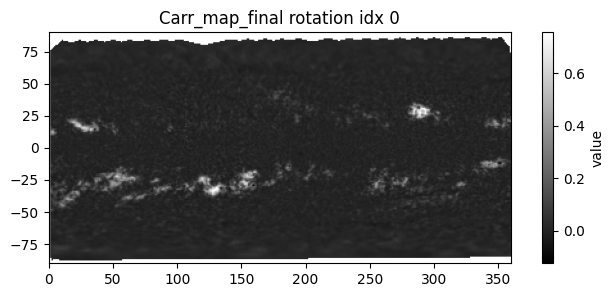

Saved rotation 1102 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1102.fits


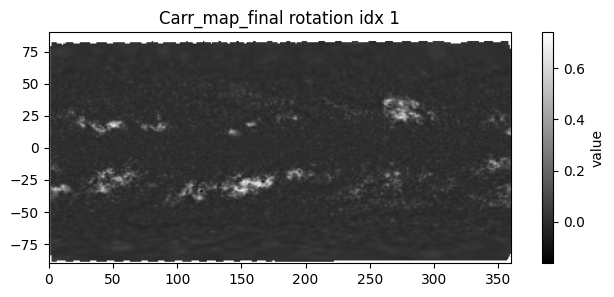

Saved rotation 1103 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1103.fits


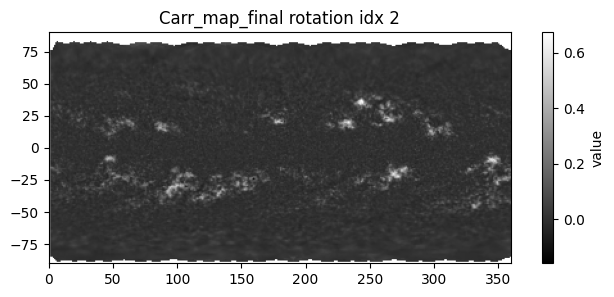

Saved rotation 1104 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1104.fits


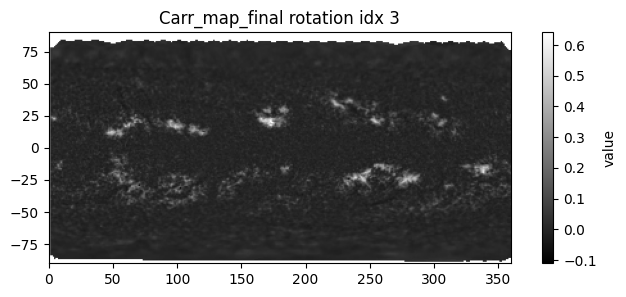

Saved rotation 1105 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1105.fits


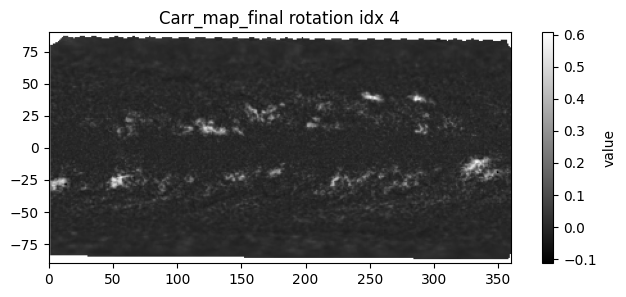

Saved rotation 1106 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1106.fits


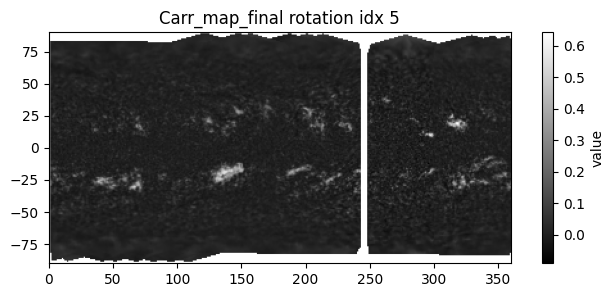

Saved rotation 1107 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1107.fits


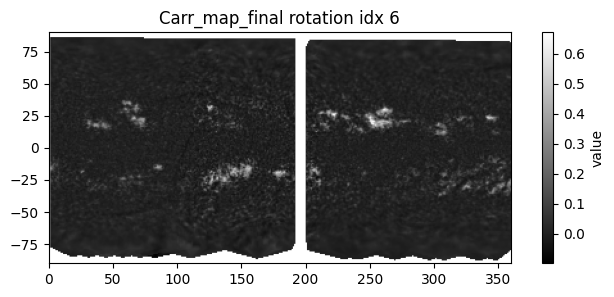

Saved rotation 1108 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1108.fits


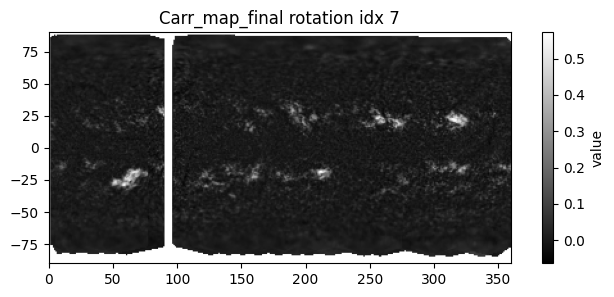

Saved rotation 1109 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1109.fits


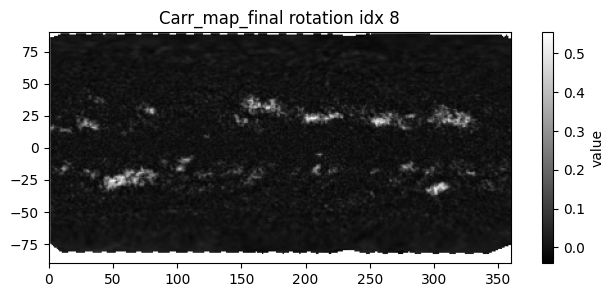

Saved rotation 1110 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1110.fits


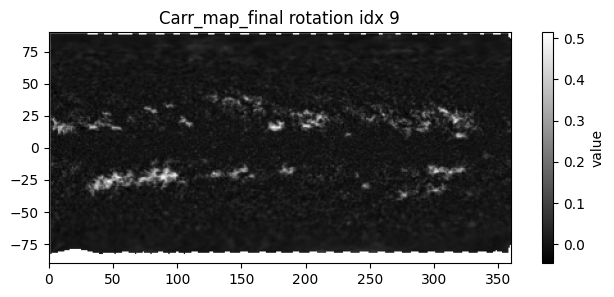

Saved rotation 1111 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1111.fits


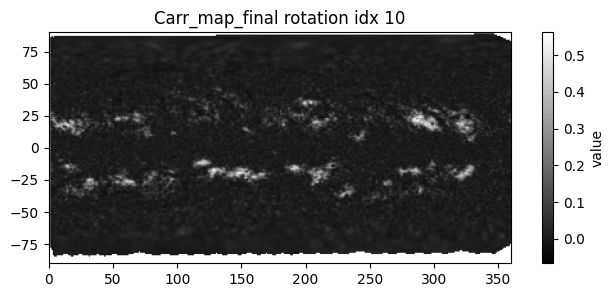

Saved rotation 1112 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1112.fits


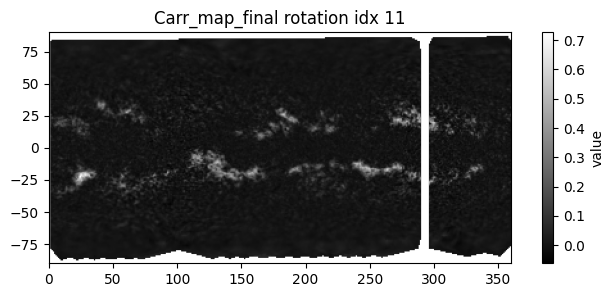

Saved rotation 1113 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1113.fits


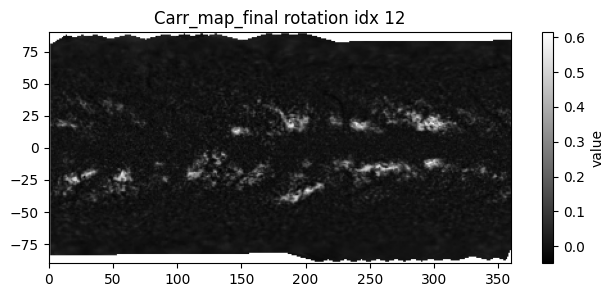

Saved rotation 1114 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1114.fits


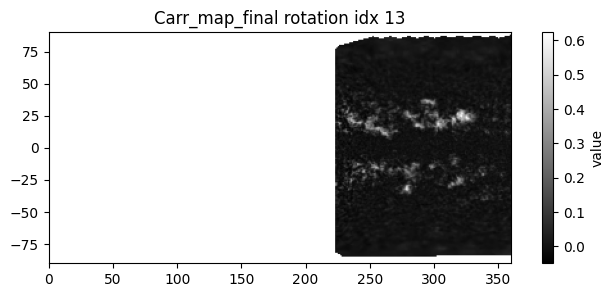

Saved rotation 1115 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1115.fits


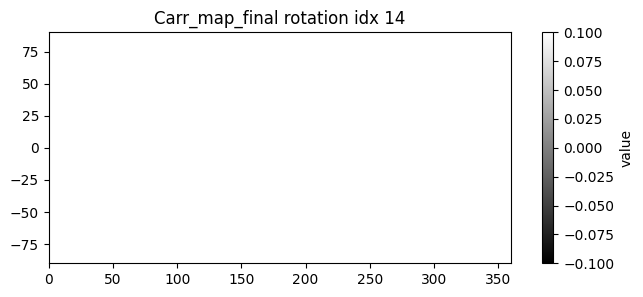

Saved rotation 1116 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1116.fits


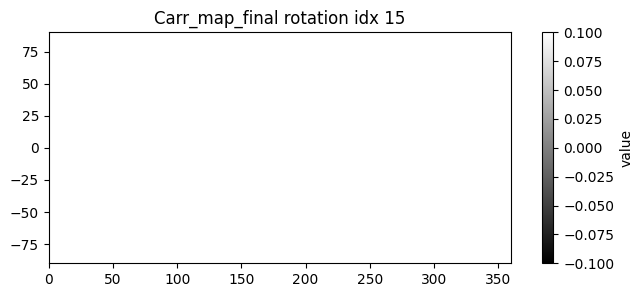

Saved rotation 1117 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1117.fits


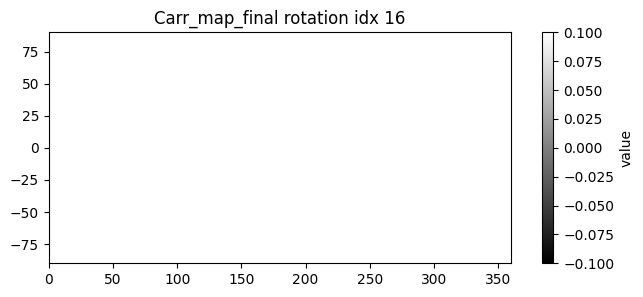

Saved rotation 1118 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1118.fits


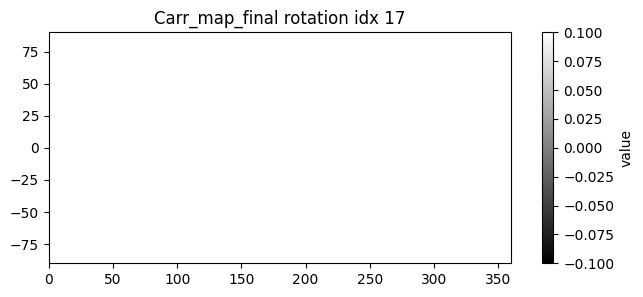

Saved rotation 1119 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1119.fits


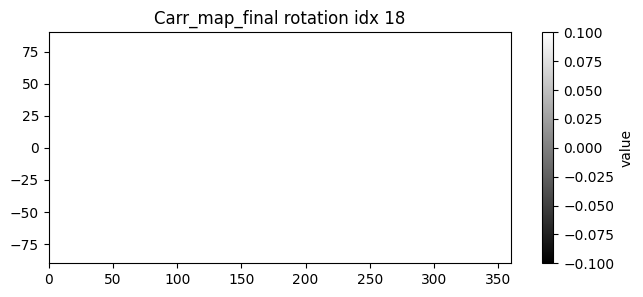

Saved rotation 1120 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1120.fits


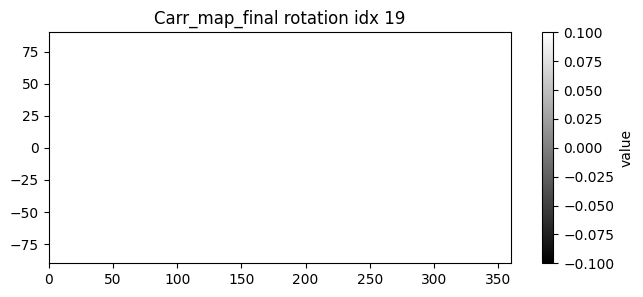

Saved rotation 1121 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1121.fits


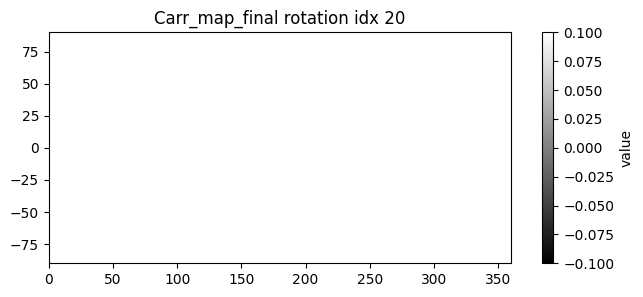

Saved rotation 1122 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1122.fits


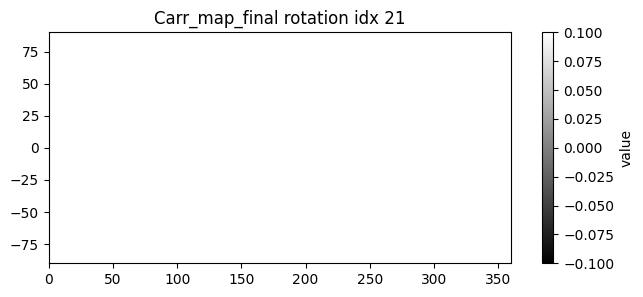

Saved rotation 1123 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1123.fits


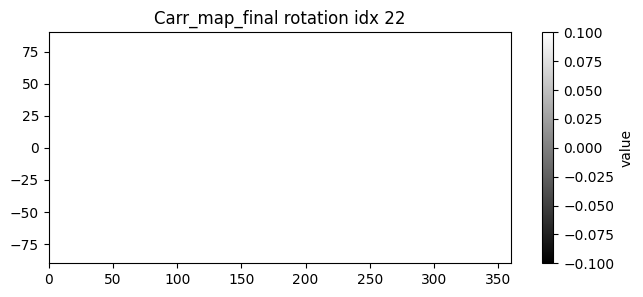

Saved rotation 1124 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1124.fits


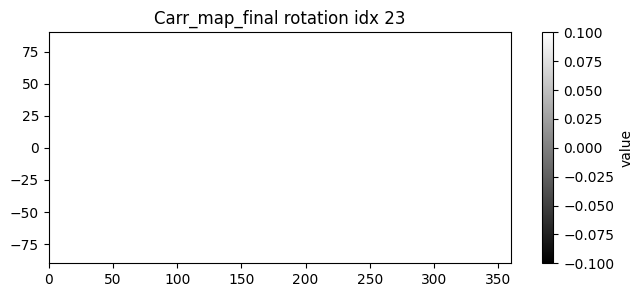

Saved rotation 1125 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1125.fits


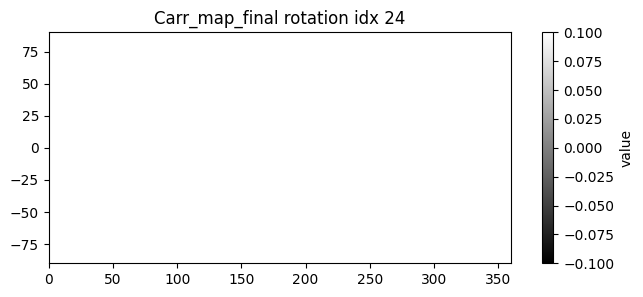

Saved rotation 1126 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1126.fits


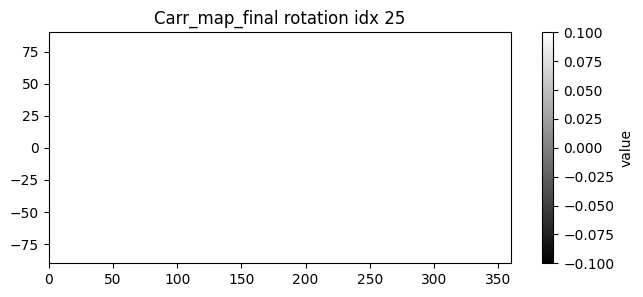

Saved rotation 1127 to /home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new_2/1127.fits


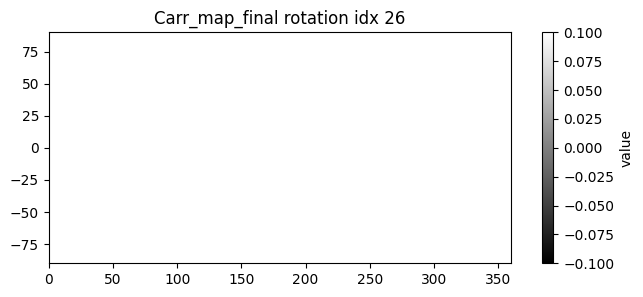

In [5]:

# ----------------------------------------------------------------------
# Build the file index (year/month/day/hour/minute -> filename)
# ----------------------------------------------------------------------

YEAR_START = 1980
YEAR_END = 2005  # inclusive — must match the df1 filter below




# ----------------------------------------------------------------------
# Carrington rotation start-date table
# ----------------------------------------------------------------------

# df1 = pd.read_csv("/home/iron-man/Documents/long_term_reconstruction/carrington_rotation_start_dates.csv")
# Filter to the SAME year range as the image index above, so every image
# actually falls inside a defined rotation window. (Previously this was
# capped at 2003 while the image scan went to 2004, so all 2004 images
# ended up lumped into the last-processed rotation.)
# df1 = df1.loc[(df1["Year"] >= YEAR_START) & (df1["Year"] <= YEAR_END)].reset_index(drop=True)


def crr_map(folder_name):

    # Carrington grid (0-360 deg)
    nlat, nlon = 180, 360
    Lon_grid, Lat_grid = np.meshgrid(
        np.linspace(0, 360, nlon, endpoint=False),
        np.linspace(-90, 90, nlat)
    )

    def zero_grid():
        return np.zeros((nlat, nlon), dtype=float)

    # ------------------------------------------------------------------
    # PHASE 1: accumulate. A single global sum/count grid per rotation
    # index, filled in across ALL rotations before anything is finalized
    # or written to disk. This lets a wrap contribution go to i-1 *or*
    # i+1 regardless of which rotation is processed first — no rotation
    # is saved until every image that could contribute to it (directly,
    # or via wrap from a neighbor) has been visited.
    # ------------------------------------------------------------------
    Carr_sum = {i: zero_grid() for i in range(len(df1))}
    Carr_count = {i: zero_grid() for i in range(len(df1))}

    for i in range(len(df1)):
        print(f"\n=== Accumulating rotation index {i} id={df1['Rotation'].iloc[i]} ===")

        # determine datetime mask for this rotation
        row_1 = df1.iloc[i]
        row_2 = df1.iloc[i + 1] if (i + 1) < len(df1) else None

        date_1 = row_1["Date"]
        date_2 = row_2["Date"] if row_2 is not None else None
        if date_2 is not None:
            mask = (df["Date"] >= date_1) & (df["Date"] <= date_2)
        else:
            mask = df["Date"] >= date_1

        list_datetime = df.loc[mask, "datetime"].tolist()
        list_value = df.loc[mask, "value"].tolist()

        # Disk geometry (full arrays)
        npix = 256
        disk_radius_px = npix * 0.898 / 2
        grid_x, grid_y = np.meshgrid(np.arange(npix), np.arange(npix))
        x_full = (grid_x - npix / 2) / disk_radius_px
        y_full = (grid_y - npix / 2) / disk_radius_px
        R2_full = x_full ** 2 + y_full ** 2
        visible_full = R2_full <= 1.0
        z_full = np.sqrt(np.clip(1 - R2_full, 0.0, None))

        x = x_full[visible_full]
        y = y_full[visible_full]
        z = z_full[visible_full]

        for time_value, value_name in zip(list_datetime, list_value):
            dt = time_value.to_pydatetime() if hasattr(time_value, "to_pydatetime") else time_value
            filename_format = dt.strftime("%Y%m%d_%H%M")
            year, month = dt.year, dt.month
            print(filename_format)
            image_path = f"/home/iron-man/Documents/long_term_reconstruction/callibrated/Cak_Rotated/{year}/{month:02d}/{filename_format}.h5"
            # /home/iron-man/Documents/long_term_reconstruction/callibrated/Cak_Rotated/1975/01

            if not os.path.exists(image_path):
                print(f"  WARNING: image missing {image_path} — skipping")
                continue

            with h5py.File(image_path, "r") as f:
                data = f["data"][:]
            values_full = data[visible_full]

            # Carrington coordinates
            t = Time(time_value)
            L0 = sun.L0(t).to_value("deg")
            B0 = sun.B0(t).to_value("deg")
            B0_rad = np.deg2rad(B0)

            lat_deg_full = np.degrees(np.arcsin(np.clip(z * np.sin(B0_rad) + y * np.cos(B0_rad), -1, 1)))
            lon_deg_full = np.degrees(np.arctan2(x, z * np.cos(B0_rad) - y * np.sin(B0_rad)))

            # central meridian mask
            mask_central = (lon_deg_full >= -30) & (lon_deg_full <= 30)
            if not np.any(mask_central):
                continue

            lat_deg = lat_deg_full[mask_central]
            lon_deg = lon_deg_full[mask_central]
            values = values_full[mask_central]

            # absolute Carrington longitude for these pixels (can be <0 or >=360)
            lon_carr_abs = L0 + lon_deg

            weights_full = (np.cos(np.deg2rad(lon_deg_full))) ** 4
            weights_masked = weights_full[mask_central]
            weighted_values = values * weights_masked

            # def add_contribution(target_idx, lon_vals, lat_vals, val_vals, wgt_vals):
            #     """Interpolate onto the Carrington grid and accumulate into
            #     Carr_sum[target_idx] / Carr_count[target_idx]."""
            #     if target_idx is None or target_idx < 0 or target_idx >= len(df1):
            #         return
            #     if len(lon_vals) < 3:
            #         print(f"  WARNING: fewer than 3 points for {filename_format} "
            #               f"-> rotation idx {target_idx}, skipping")
            #         return
            #     pts = np.vstack((lon_vals, lat_vals)).T
            #     img = griddata(pts, val_vals, (Lon_grid, Lat_grid), method="linear")
            #     wgt = griddata(pts, wgt_vals, (Lon_grid, Lat_grid), method="linear")
            #     valid = ~np.isnan(img) & ~np.isnan(wgt)
            #     Carr_sum[target_idx][valid] += img[valid]
            #     Carr_count[target_idx][valid] += wgt[valid]

            # # --- 1) direct contribution: falls cleanly within this
            # #        rotation's own 0-360 window ---
            # mask_direct = (lon_carr_abs >= 0.0) & (lon_carr_abs < 360.0)
            # add_contribution(
            #     i,
            #     lon_carr_abs[mask_direct], lat_deg[mask_direct],
            #     weighted_values[mask_direct], weights_masked[mask_direct]
            # )

            # # --- 2) overflow (lon_carr_abs >= 360) belongs to the
            # #        EARLIER rotation, index i-1 ---
            # mask_over = lon_carr_abs >= 360.0
            # if np.any(mask_over):
            #     add_contribution(
            #         i - 1,
            #         lon_carr_abs[mask_over] - 360.0, lat_deg[mask_over],
            #         weighted_values[mask_over], weights_masked[mask_over]
            #     )

            # # --- 3) underflow (lon_carr_abs < 0) belongs to the
            # #        LATER rotation, index i+1 ---
            # mask_under = lon_carr_abs < 0.0
            # if np.any(mask_under):
            #     add_contribution(
            #         i + 1,
            #         lon_carr_abs[mask_under] + 360.0, lat_deg[mask_under],
            #         weighted_values[mask_under], weights_masked[mask_under]
            #     )

            # WRAP_MARGIN = 30.0  # degrees; mask_central is +-30deg, +buffer
            def add_contribution(target_idx, lon_vals, lat_vals, val_vals, wgt_vals):
                """Interpolate onto the Carrington grid and accumulate into
                Carr_sum[target_idx] / Carr_count[target_idx]. Longitude is
                periodic (0 == 360), but griddata doesn't know that, so
                points within WRAP_MARGIN of either edge are duplicated
                +-360deg away first, letting the triangulation wrap around
                the seam instead of treating it as a hard boundary."""
                if target_idx is None or target_idx < 0 or target_idx >= len(df1):
                    return
                if len(lon_vals) < 3:
                    print(f"  WARNING: fewer than 3 points for {filename_format} "
                          f"-> rotation idx {target_idx}, skipping")
                    return

                lon_vals = np.asarray(lon_vals)
                lat_vals = np.asarray(lat_vals)
                val_vals = np.asarray(val_vals)
                wgt_vals = np.asarray(wgt_vals)

                # near_low = lon_vals <= WRAP_MARGIN
                # near_high = lon_vals >= (360.0 - WRAP_MARGIN)

                lon_ext = [lon_vals]
                lat_ext = [lat_vals]
                val_ext = [val_vals]
                wgt_ext = [wgt_vals]

                # if np.any(near_low):
                #     lon_ext.append(lon_vals[near_low] + 360.0)
                #     lat_ext.append(lat_vals[near_low])
                #     val_ext.append(val_vals[near_low])
                #     wgt_ext.append(wgt_vals[near_low])
                # if np.any(near_high):
                #     lon_ext.append(lon_vals[near_high] - 360.0)
                #     lat_ext.append(lat_vals[near_high])
                #     val_ext.append(val_vals[near_high])
                #     wgt_ext.append(wgt_vals[near_high])

                lon_ext = np.concatenate(lon_ext)
                lat_ext = np.concatenate(lat_ext)
                val_ext = np.concatenate(val_ext)
                wgt_ext = np.concatenate(wgt_ext)

                pts = np.vstack((lon_ext, lat_ext)).T
                img = griddata(pts, val_ext, (Lon_grid, Lat_grid), method="linear")
                wgt = griddata(pts, wgt_ext, (Lon_grid, Lat_grid), method="linear")
                valid = ~np.isnan(img) & ~np.isnan(wgt)
                Carr_sum[target_idx][valid] += img[valid]
                Carr_count[target_idx][valid] += wgt[valid]

            # --- 1) direct contribution: falls cleanly within this
            #        rotation's own 0-360 window ---
            mask_direct = (lon_carr_abs >= 0.0) & (lon_carr_abs < 360.0)
            add_contribution(
                i,
                lon_carr_abs[mask_direct], lat_deg[mask_direct],
                weighted_values[mask_direct], weights_masked[mask_direct]
            )

            # --- 2) overflow (lon_carr_abs >= 360) belongs to the
            #        EARLIER rotation, index i-1 ---
            mask_over = lon_carr_abs >= 360.0
            if np.any(mask_over):
                add_contribution(
                    i - 1,
                    lon_carr_abs[mask_over] - 360.0, lat_deg[mask_over],
                    weighted_values[mask_over], weights_masked[mask_over]
                )

            # --- 3) underflow (lon_carr_abs < 0) belongs to the
            #        LATER rotation, index i+1 ---
            mask_under = lon_carr_abs < 0.0
            if np.any(mask_under):
                add_contribution(
                    i + 1,
                    lon_carr_abs[mask_under] + 360.0, lat_deg[mask_under],
                    weighted_values[mask_under], weights_masked[mask_under]
                )
    # ------------------------------------------------------------------
    # PHASE 2: finalize + save. All rotations have now received every
    # contribution (direct and wrapped from both neighbors), so it's
    # safe to divide and write each one out.
    # ------------------------------------------------------------------
    save_dir = f"/home/iron-man/Documents/long_term_reconstruction/callibrated/{folder_name}"
    os.makedirs(save_dir, exist_ok=True)

    for i in range(len(df1)):
        Carr_map_final = np.divide(
            Carr_sum[i], Carr_count[i],
            out=np.full_like(Carr_sum[i], np.nan),
            where=Carr_count[i] > 0
        )

        out_file_name = f"{df1['Rotation'].iloc[i]}.fits"
        output_path = os.path.join(save_dir, out_file_name)
        fits.writeto(output_path, Carr_map_final, overwrite=True)
        print(f"Saved rotation {df1['Rotation'].iloc[i]} to {output_path}")

        # optional preview
        plt.figure(figsize=(8, 3))
        plt.title(f"Carr_map_final rotation idx {i}")
        plt.imshow(Carr_map_final, origin="lower", cmap="gray", extent=[0, 360, -90, 90])
        plt.colorbar(label="value")
        plt.show()

    return None


for folder_name in ["carrington_map_using_callibrated_Cak_new"]:
    crr_map(folder_name)

# Carrington map to full disk

In [7]:
Cak_path = "/home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new"
Carrington_no = []
Carrington_no = []

if os.path.exists(Cak_path): 
    crr_series = os.listdir(Cak_path)
    for filename in crr_series:                # e.g. "1648.fits"
        Carrington_number = filename.split(".")[0]    # → "1648"
            
        if Carrington_number.isdigit():
            Carrington_number = int(Carrington_number)
            Carrington_no.append(Carrington_number)

            
df1 = pd.read_csv("/home/iron-man/Documents/long_term_reconstruction/carrington_rotation_start_dates.csv")  
df1 = df1[df1["Rotation"].isin(Carrington_no)]
print(df1)

      Rotation  Year  Month      Day        Date   Julian Date
629        619  1900      1   4.0862  1900.00846  2.415024e+06
630        620  1900      1  31.4267  1900.08336  2.415051e+06
631        621  1900      2  27.7648  1900.15826  2.415078e+06
632        622  1900      3  27.0782  1900.23309  2.415106e+06
633        623  1900      4  23.3502  1900.30781  2.415133e+06
...        ...   ...    ...      ...         ...           ...
2044      2034  2005      9   4.4215  2005.67513  2.453618e+06
2045      2035  2005     10   1.6920  2005.74984  2.453645e+06
2046      2036  2005     10  28.9835  2005.82461  2.453672e+06
2047      2037  2005     11  25.2902  2005.89943  2.453700e+06
2048      2038  2005     12  22.6113  2005.97428  2.453727e+06

[1420 rows x 6 columns]


In [ ]:
nlat = 180
npix = 256
disk_radius=80
count=0
disk_radius_px=npix*0.898/2
for value in sorted(Carrington_no):
# for value in [1389,1390,1391]:
    cak_path_center = f"/home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new/{value}.fits"    # e.g.  "{Cr}.fits"
    cak_path_right = f"/home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new/{value-1}.fits"
    cak_path_left = f"/home/iron-man/Documents/long_term_reconstruction/callibrated/carrington_map_using_callibrated_Cak_new/{value+1}.fits"
    print(value)
    # load magnetogram Carrington maps 
    Br_center = fits.getdata(cak_path_center)
    Br_center[:, 0] = Br_center[:, 1]

    
    # get times
    row_1 = df1[df1["Rotation"] == value]
    row_2 = df1[df1["Rotation"] == (value + 1)]

    if row_1.empty or row_2.empty:
        continue

    row_1 = row_1.iloc[0]
    row_2 = row_2.iloc[0]
    year, month = int(row_1["Year"]), int(row_1["Month"])
    day_fraction = float(row_1["Day"])
    day, frac = int(day_fraction), day_fraction - int(day_fraction)
    t_start = datetime(year, month, day) + timedelta(days=frac)

    year, month = int(row_2["Year"]), int(row_2["Month"])
    day_fraction = float(row_2["Day"])
    day, frac = int(day_fraction), day_fraction - int(day_fraction)
    t_end = datetime(year, month, day) + timedelta(days=frac)

    # filter df between t_start and t_end
    mask = (df["datetime"] >= t_start) & (df["datetime"] < t_end)
    df_filtered = df[mask]




    
    for time_value in df_filtered["datetime"]:
        t = Time(time_value)
        L0 = sun.L0(t).to_value("deg")
        B0 = sun.B0(t).to_value("deg")
        

        # ---- Decide whether to merge maps ----
        if L0 + disk_radius > 360:
            if os.path.isfile(cak_path_right):
                Br_right = fits.getdata(cak_path_right)
                Br_right[:, 0] = Br_right[:, 1]
                # near the right edge → merge center + right
                Br = np.hstack((Br_center, Br_right))
                Br = Br[:,int(L0)-180:int(L0)+180]
                lon = np.linspace(0, 360, 360, endpoint=False)
                L0_value = 180 
            else:
                continue

        elif L0 <= disk_radius:
            if os.path.isfile(cak_path_left):
                Br_left = fits.getdata(cak_path_left)
                Br_left[:, 0] = Br_left[:, 1]
                # near the left edge → merge left + center
                # Br = np.hstack((Br_left[:,180:], Br_center[:,:180]))
                Br = np.hstack((Br_left, Br_center))
                L0=L0+360         # shift L0 by +360 because the left map is now in [-360,0]
                Br = Br[:,int(L0)-180:int(L0)+180]
                lon = np.linspace(0, 360, 360, endpoint=False)
                # L0_value = L0 + 180
                L0_value = 180 
            else:
                continue

        else:
            # use only one Carrington map → 360 longitude grid
            Br = Br_center
            nlon = 360
            lon = np.linspace(0, 360, 360, endpoint=False)
            L0_value= L0

        # build Lon/Lat grid matching Br shape
        nlat, nlon_actual = Br.shape
        # lon = np.linspace(0, nlon, nlon)
        lat = np.linspace(-90, 90, nlat)                        # uniform in sin(latitude)
        
        Lon, Lat = np.meshgrid(lon, lat)

        Lon_rad = np.deg2rad(Lon - L0_value)
        Lat_rad = np.deg2rad(Lat)
        B0_rad  = np.deg2rad(B0)

                
        r=1
        x = r*(np.cos(Lat_rad)*np.sin(Lon_rad))                                                      # x = r cos Θ sin(Φ − Φ0),
        y = r*(np.sin(Lat_rad)*np.cos(B0_rad) - np.cos(Lat_rad)*np.cos(Lon_rad)*np.sin(B0_rad))      # y = r[sin Θ cos B0 − cos Θ cos(Φ − Φ0)sin B0] , 
        z = r*(np.sin(Lat_rad)*np.sin(B0_rad) + np.cos(Lat_rad)*np.cos(Lon_rad)*np.cos(B0_rad))      # z = r[sin Θ sin B0 + cos Θ cos(Φ − Φ0) cos B0]
        
        visible = z > 0
        X = x[visible]
        Y = y[visible]
        values = Br[visible]

        # scale to pixel coords
        X_pix = (X * disk_radius_px + npix/2).ravel()
        Y_pix = (Y * disk_radius_px + npix/2).ravel()
        
        # make pixel grid
        grid_x, grid_y = np.meshgrid(np.arange(npix), np.arange(npix))
        # interpolate onto image plane
        Br_cropped = griddata(
            points=(X_pix, Y_pix),
            values=values.ravel(),
            xi=(grid_x, grid_y),
            method="linear",
            fill_value= np.nan
        )
        
        R = np.sqrt((grid_x - npix/2)**2 + (grid_y - npix/2)**2)
        Br_cropped[R > disk_radius_px] = np.nan
        


        mask_inside = R <= disk_radius_px  # inside solar disk

        # plt.imshow(Br_cropped,cmap="gray",origin="lower")
        # plt.show()
        # total and NaN pixel count inside disk
        total_inside = np.sum(mask_inside)
        nan_inside = np.sum(np.isnan(Br_cropped[mask_inside]))
        # fraction of NaN pixels inside the disk
        nan_fraction = nan_inside / total_inside
        if nan_fraction<=0.01:
            save_dir = f"/home/iron-man/Documents/long_term_reconstruction/callibrated/Cropped_cak_new/{time_value.year}/{time_value.month:02d}"
            # Ensure output directory exists
            os.makedirs(save_dir, exist_ok=True)
            file_name = f"{time_value.strftime('%Y%m%d_%H%M')}.fits"
            output_path = os.path.join(save_dir, file_name)
            # Save Br_cropped as FITS
            hdu = fits.PrimaryHDU(Br_cropped)       # 19070208_0827.h5
            hdul = fits.HDUList([hdu])
            # Optionally add metadata to header
            hdr = hdul[0].header
            hdr['DATE'] = time_value.strftime("%Y-%m-%d %H:%M:%S")
            hdr['L0'] = L0
            hdr['B0'] = B0
            hdr['DISKRAD'] = disk_radius
            hdr['CARR_ROT'] = value

            # Write file (overwrite if exists)
            hdul.writeto(output_path, overwrite=True)
            print(f"completed{file_name}")
print(f"completed") 


619
620
621
622
623
624
625
626
627
628
629
630
631
632
633
634
635
636
637
638
639
640
641
642
643
644
645
646
647
648
649
650
651
652
653
654
655
656
657
658
659
660
661
662
663
664
665
666
667
668
669
670
671
672
673
674
675
676
677
678
679
680
681
682
683
684
685
686
687
688
689
690
691
692
693
694
695
696
697
698
699
700
701
702
703
704
705
706
707
708
709
710
711
712
713
714


/home/iron-man/jupyter-env/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/iron-man/jupyter-env/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/iron-man/jupyter-env/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/iron-man/jupyter-env/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


completed19070227_0844.fits
completed19070226_0835.fits
completed19070226_0859.fits
completed19070228_0900.fits
completed19070225_0848.fits
completed19070303_0929.fits
completed19070301_0831.fits
completed19070304_0822.fits
completed19070302_0913.fits
completed19070307_0822.fits
completed19070303_0821.fits
completed19070305_0903.fits
completed19070305_0827.fits
completed19070306_0820.fits
completed19070301_0909.fits
completed19070307_0853.fits
completed19070304_0830.fits
715
completed19070323_0837.fits
completed19070318_0831.fits
completed19070312_0820.fits
completed19070317_0913.fits
completed19070319_0812.fits
completed19070322_0829.fits
completed19070310_0856.fits
completed19070318_0810.fits
completed19070331_0818.fits
completed19070325_0820.fits
completed19070309_0917.fits
completed19070325_0836.fits
completed19070314_0915.fits
completed19070324_0813.fits
completed19070315_0837.fits
completed19070320_0912.fits
completed19070320_0834.fits
completed19070328_0839.fits
completed1907031